# Chapitre 14 - Exercices 14.22 à 14.25

Ce notebook traite les derniers exercices du chapitre :

- **14.22** : PageRank (normalisation et méthode de la puissance) ;
- **14.23** : l'algorithme de factorisation en matrices non négatives (NMF) vu comme un
  algorithme MM (minoration–maximisation) ;
- **14.24** : NMF de rang 1 et ajustement proportionnel itératif ;
- **14.25** : NMF contre ACP sur les chiffres « 2 » manuscrits.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import ch14_non_supervise_complements as nsc
from esl import datasets
set_style()

## Exercice 14.22 : PageRank

**Énoncé (reformulé).**

(a) Montrer que la définition (14.108) implique que la somme des PageRanks $p_i$ vaut
$N$, le nombre de pages web.

(b) Écrire un programme calculant les PageRanks par la méthode de la puissance à partir
de la formulation (14.107), et l'appliquer au réseau de la figure 14.47 du livre.

### Rappels (section 14.10)

On note $L_{ij} = 1$ si la page $j$ pointe vers la page $i$ (0 sinon), et
$c_j = \sum_iL_{ij}$ le nombre de liens sortants de la page $j$. Les PageRanks sont
définis par la relation récursive (14.107) :
$$p_i = (1 - d) + d\sum_{j=1}^N\frac{L_{ij}}{c_j}\,p_j,$$
avec $d = 0{,}85$ ; matriciellement (14.108) :
$$p = (1-d)\,e + d\,LD_c^{-1}p,\qquad e = (1,\dots,1)^T,\quad D_c = \operatorname{diag}(c).$$
Chaque page $j$ distribue un « vote » total égal à $p_j$, réparti également entre les
$c_j$ pages vers lesquelles elle pointe.

### (a) La somme des PageRanks vaut $N$

On suppose que chaque page a au moins un lien sortant ($c_j \ge 1$, sinon $D_c^{-1}$
n'est pas défini). La somme de la colonne $j$ de $LD_c^{-1}$ vaut
$\sum_iL_{ij}/c_j = c_j/c_j = 1$, c'est-à-dire $e^TLD_c^{-1} = e^T$.

Multiplions (14.108) à gauche par $e^T$ :
$$e^Tp = (1-d)\,e^Te + d\,e^TLD_c^{-1}p = (1-d)N + d\,e^Tp.$$
Donc $(1 - d)\,e^Tp = (1-d)N$, et comme $d < 1$ :
$$\boxed{\sum_{i=1}^Np_i = e^Tp = N.}$$
La moyenne des PageRanks vaut 1 ; la normalisation $e^Tp = N$ utilisée pour écrire
(14.109) n'est donc pas une contrainte supplémentaire, elle découle de la définition.

### Le point de vue « chaîne de Markov »

Grâce à (a), on peut écrire $(1-d)e = (1-d)ee^Tp/N$, d'où $p = Ap$ avec
$$A = (1-d)\frac{ee^T}{N} + d\,LD_c^{-1}.\qquad(14.109)$$
Les coefficients de $A$ sont positifs et ses colonnes somment à 1 : $A$ est la matrice
de transition d'une chaîne de Markov (le **surfeur aléatoire** : depuis la page $j$, il
suit un lien sortant au hasard avec probabilité $d$, ou saute sur une page uniforme avec
probabilité $1-d$). $p/N$ est la loi stationnaire de cette chaîne, et la valeur propre 1
est la plus grande (en module) de $A$ : la **méthode de la puissance**
$p_k \leftarrow Ap_{k-1}$, $p_k \leftarrow Np_k/e^Tp_k$ (14.110) converge vers $p$.

### (b) Programme et vérification sur l'exemple du livre

La fonction `pagerank_power` implémente (14.110). On vérifie d'abord l'exemple de la
figure 14.46 (matrice (14.111)), pour lequel le livre donne
$\hat p = (1{,}49;\ 0{,}78;\ 1{,}58;\ 0{,}15)$.

In [2]:
L46 = np.array([[0, 0, 1, 0],
                [1, 0, 0, 0],
                [1, 1, 0, 1],
                [0, 0, 0, 0]])
p46, _ = nsc.pagerank_power(L46)
print("PageRanks (figure 14.46) :", p46.round(2))

PageRanks (figure 14.46) : [1.49 0.78 1.58 0.15]


**Réseau de la figure 14.47.** En lisant les flèches de la figure, on obtient les liens
(page source $\to$ page cible) :
$1\to2$, $1\to3$, $2\to3$, $3\to1$, $4\to1$, $4\to3$, $5\to3$, $6\to2$, $6\to5$.
Chaque page a au moins un lien sortant.

In [3]:
edges = [(1, 2), (1, 3), (2, 3), (3, 1), (4, 1), (4, 3), (5, 3), (6, 2), (6, 5)]
N6 = 6
L47 = np.zeros((N6, N6))
for j, i in edges:                       # la page j pointe vers la page i
    L47[i - 1, j - 1] = 1
print("matrice L :\n", L47.astype(int))
print("liens sortants c :", L47.sum(0).astype(int))

matrice L :
 [[0 0 1 1 0 0]
 [1 0 0 0 0 1]
 [1 1 0 1 1 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 1]
 [0 0 0 0 0 0]]
liens sortants c : [2 1 1 2 1 2]


In [4]:
p47, hist47 = nsc.pagerank_power(L47, d=0.85)
p47_lin = nsc.pagerank_linear(L47, d=0.85)
for k in range(N6):
    print("page %d : PageRank = %.4f" % (k + 1, p47[k]))
print("somme = %.6f ; écart à la résolution directe du système : %.1e"
      % (p47.sum(), np.abs(p47 - p47_lin).max()))

page 1 : PageRank = 2.1234
page 2 : PageRank = 1.1162
page 3 : PageRank = 2.2467
page 4 : PageRank = 0.1500
page 5 : PageRank = 0.2137
page 6 : PageRank = 0.1500
somme = 6.000000 ; écart à la résolution directe du système : 1.6e-13


**Interprétation.** Les pages 4 et 6 ne reçoivent aucun lien : elles ont le PageRank
minimal $1 - d = 0{,}15$. La page 5 n'est citée que par la page 6 (qui a 2 liens
sortants) : $p_5 = 0{,}15 + 0{,}85\times 0{,}15/2 = 0{,}214$. Les pages 1 et 3 se citent
mutuellement et la page 3 reçoit beaucoup de liens : ce sont les plus importantes.

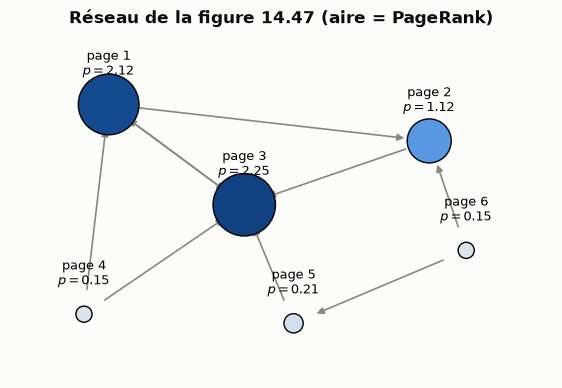

In [5]:
pos = np.array([[0.0, 2.0], [2.6, 1.6], [1.1, 0.9], [-0.2, -0.3], [1.5, -0.4], [2.9, 0.4]])
fig, ax = plt.subplots(figsize=(7, 4.5))
for j, i in edges:
    a, b = pos[j - 1], pos[i - 1]
    ax.annotate("", xy=b, xytext=a,
                arrowprops=dict(arrowstyle="-|>", color=GRAY, lw=1.2,
                                shrinkA=18, shrinkB=18))
ax.scatter(pos[:, 0], pos[:, 1], s=900 * p47, c=p47, cmap=SEQ, vmin=0, vmax=p47.max(),
           edgecolors="k", zorder=3)
for k in range(N6):
    ax.text(pos[k, 0], pos[k, 1] + 0.32, "page %d\n$p=%.2f$" % (k + 1, p47[k]),
            ha="center", fontsize=9)
ax.set_xlim(-0.8, 3.6); ax.set_ylim(-1.0, 2.8)
ax.set_axis_off()
ax.set_title("Réseau de la figure 14.47 (aire = PageRank)")
plt.show()

**Vitesse de convergence.** L'erreur de la méthode de la puissance décroît
géométriquement, au rythme du module de la deuxième valeur propre de $A$, qui est au
plus $d = 0{,}85$.

modules des valeurs propres de A : [1.    0.601 0.601 0.    0.    0.   ]


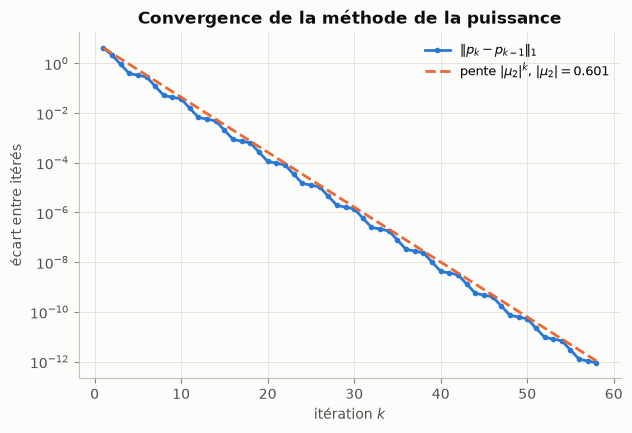

In [6]:
A47 = nsc.pagerank_matrix(L47)
ev = np.sort(np.abs(np.linalg.eigvals(A47)))[::-1]
print("modules des valeurs propres de A :", ev.round(4))
fig, ax = plt.subplots(figsize=(7, 4.5))
k = np.arange(1, len(hist47) + 1)
ax.semilogy(k, hist47, "o-", ms=3, color=BLUE, label=r"$\|p_k - p_{k-1}\|_1$")
ax.semilogy(k, hist47[0] * ev[1] ** (k - 1), "--", color=ORANGE,
            label=r"pente $|\mu_2|^k$, $|\mu_2| = %.3f$" % ev[1])
ax.set_xlabel("itération $k$")
ax.set_ylabel("écart entre itérés")
ax.set_title("Convergence de la méthode de la puissance")
ax.legend()
plt.show()

**Simulation du surfeur aléatoire.** On simule $200\,000$ pas de la chaîne de Markov
de matrice $A$ ; les fréquences de visite, multipliées par $N$, approchent les PageRanks.

In [7]:
rng = np.random.RandomState(0)
n_steps = 200_000
cum = np.cumsum(A47, axis=0)                 # colonne j : loi de la page suivante
u = rng.rand(n_steps)
state, visits = 0, np.zeros(N6)
for t_ in range(n_steps):
    state = np.searchsorted(cum[:, state], u[t_])
    visits[state] += 1
freq = N6 * visits / n_steps

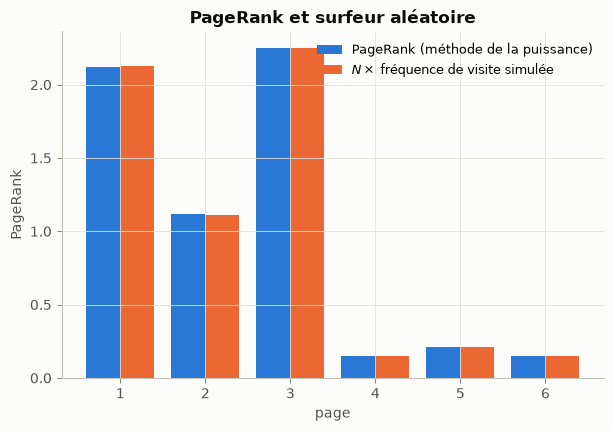

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.5))
idx = np.arange(1, N6 + 1)
ax.bar(idx - 0.2, p47, 0.4, color=BLUE, label="PageRank (méthode de la puissance)")
ax.bar(idx + 0.2, freq, 0.4, color=ORANGE, label=r"$N\times$ fréquence de visite simulée")
ax.set_xlabel("page"); ax.set_ylabel("PageRank")
ax.set_xticks(idx)
ax.set_title("PageRank et surfeur aléatoire")
ax.legend()
plt.show()